# 09 · Model deployment
PyTorch → **ONNX** (calibrated softmax baked in) → **ONNX Runtime** (CPU / CUDA / TensorRT / CoreML execution providers) →
**FastAPI** service → **Docker** image → **Kubernetes** (HPA, PDB, NetworkPolicy) with optional **Triton** GPU serving
(**TensorRT** FP16) and **DeepStream** for streaming ROI detection. **Core ML** export targets on-device Apple inference.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
FIG = ROOT / 'reports' / 'figures'
def show(name, width=900): display(Image(filename=str(FIG / f'{name}.png'), width=width))

{
 "onnx_fp32": {
  "max_abs_diff_vs_pytorch": 2.980232238769531e-07,
  "prediction_agreement": 1.0,
  "test_accuracy": 0.92,
  "size_mb": 2.88
 },
 "onnx_int8": {
  "max_abs_diff_vs_pytorch": 0.015498876571655273,
  "prediction_agreement": 1.0,
  "test_accuracy": 0.92,
  "size_mb": 0.87
 }
}


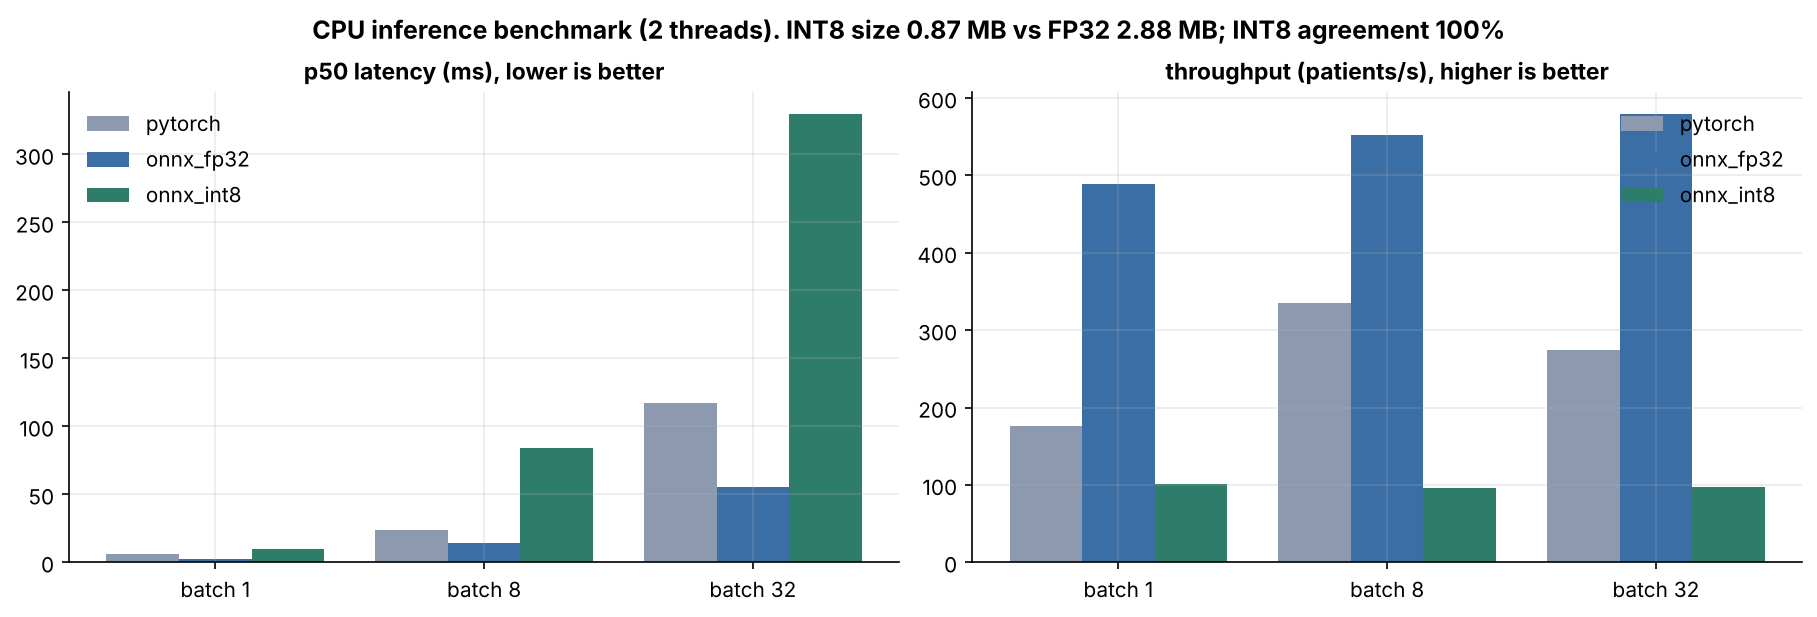

In [2]:
bm = json.load(open(ROOT / 'reports/metrics/deployment_benchmark.json'))
print(json.dumps(bm['parity'], indent=1)); show('32_deployment_benchmark', 1000)

In [3]:
from ad_mm.deployment.onnx_inference import ADPredictor
from ad_mm.preprocessing.tabular import NUMERIC
ds = pd.read_csv(ROOT / 'data/processed/multimodal_dataset.csv'); r = ds[ds.split == 'test'].iloc[3]
pred = ADPredictor()
out = pred.predict(ROOT / 'data/raw/imaging' / r.file, r.note_text, r[NUMERIC].to_dict())
print('true:', r.label); print(json.dumps(out, indent=1))

true: LMCI
{
 "prediction": "LMCI",
 "confidence": 0.9829,
 "probabilities": {
  "CN": 0.0011,
  "SMC": 0.0012,
  "EMCI": 0.0069,
  "LMCI": 0.9829,
  "AD": 0.0079
 },
 "modality_weights": {
  "image": 0.204,
  "text": 0.183,
  "tabular": 0.613
 },
 "modalities_used": [
  "image",
  "text",
  "tabular"
 ],
 "refer_to_clinician": false,
 "image_qc": {
  "format": "dcm",
  "qc_pass": true,
  "snr": 7.253,
  "noise_index": 0.064,
  "contrast": 0.799,
  "p1": 0.0,
  "p99": 1.0,
  "mask_fraction": 0.485
 },
 "model_version": "ad_mm_fusion",
 "execution_providers": [
  "CPUExecutionProvider"
 ],
 "latency_ms": 125.1,
 "disclaimer": "Research use only. Not a medical device. Decision support for qualified clinicians."
}


In [4]:
# Same patient with a missing modality (no imaging): the model re-weights the remaining modalities
print(json.dumps({k: v for k, v in pred.predict(None, r.note_text, r[NUMERIC].to_dict()).items() if k in ('prediction', 'confidence', 'modality_weights')}, indent=1))

{
 "prediction": "LMCI",
 "confidence": 0.9876,
 "modality_weights": {
  "image": 0.0,
  "text": 0.23,
  "tabular": 0.77
 }
}


In [5]:
from fastapi.testclient import TestClient
from ad_mm.deployment.serve_api import app
with TestClient(app) as c:
    with open(ROOT / 'data/raw/imaging' / r.file, 'rb') as f:
        resp = c.post('/predict', files={'image': (Path(r.file).name, f)}, data={'note': r.note_text, 'numeric': json.dumps({'age': float(r.age), 'mmse': float(r.mmse)})})
    print(resp.status_code, resp.json()['prediction'], resp.json()['probabilities']); print(c.get('/metrics').text)

{"ts":"2026-10-12 15:16:15,834","level":"INFO","msg":{"request_id": "08ecc3b7-07a2-4292-9068-1eff99934dca", "prediction": "EMCI", "confidence": 0.8457, "modalities": ["image", "text", "tabular"], "model_version": "ad_mm_fusion"}}


{"ts":"2026-10-12 15:16:15,837","level":"INFO","msg":HTTP Request: POST http://testserver/predict "HTTP/1.1 200 OK"}


{"ts":"2026-10-12 15:16:15,846","level":"INFO","msg":HTTP Request: GET http://testserver/metrics "HTTP/1.1 200 OK"}


200 EMCI {'CN': 0.0192, 'SMC': 0.0582, 'EMCI': 0.8457, 'LMCI': 0.0625, 'AD': 0.0144}
ad_mm_requests_total 1
ad_mm_errors_total 0
ad_mm_latency_ms_sum 39.8
ad_mm_referrals_total 0
ad_mm_predictions_total{class="EMCI"} 1



In [6]:
for f in ['deployment/docker/Dockerfile', 'deployment/k8s/ad-mm-deployment.yaml', 'deployment/triton/model_repository/ad_mm/config.pbtxt']:
    print('=' * 20, f); print((ROOT / f).read_text()[:900])

==================== deployment/docker/Dockerfile
# Multimodal AD inference service: CPU image (ONNX Runtime). For GPU see Dockerfile.gpu.
FROM python:3.11-slim AS base

ENV PYTHONDONTWRITEBYTECODE=1 PYTHONUNBUFFERED=1 PIP_NO_CACHE_DIR=1 \
    PYTHONPATH=/app/src AD_MM_MODEL_PATH=/app/models/ad_mm_fusion.onnx

RUN apt-get update && apt-get install -y --no-install-recommends libgl1 libglib2.0-0 && rm -rf /var/lib/apt/lists/*
WORKDIR /app

COPY deployment/docker/requirements-serve.txt .
RUN pip install -r requirements-serve.txt

# code + inference artifacts only (no training data, no PHI)
COPY configs/ configs/
COPY src/ src/
COPY models/ad_mm_fusion.onnx models/tabular_transformer.json models/
COPY models/tokenizer/ models/tokenizer/
COPY data/interim/image_template.npy data/interim/

RUN useradd -u 10001 -m appuser && chown -R appuser /app
USER 10001
EXPOSE 8080
HEALTHCHECK --interval=30s --timeout=5s CMD python -c "import urllib.reques
==================== deployment/k8s/ad-mm-deploym